<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A07_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Був присутній на парі**

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("unmoved/cure-the-princess")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cure-the-princess' dataset.
Path to dataset files: /kaggle/input/cure-the-princess


In [4]:
import os
df = pd.read_csv(os.path.join(path, 'data.csv'))

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету



In [5]:
print(f"Розмір датасету: {df.shape}")
display(df.head())
df.info()

Розмір датасету: (2338, 14)


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
missing_values = df.isnull().sum()
print("Кількість пропущених значень за ознаками:")
display(missing_values)
print(f"Загальна кількість пропусків: {missing_values.sum()}")

duplicates_count = df.duplicated().sum()
print(f"\nКількість дублікатів рядків: {duplicates_count}")

Кількість пропущених значень за ознаками:


,0
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Загальна кількість пропусків: 0

Кількість дублікатів рядків: 0


In [7]:
df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
**Пропуски та дублікати:** у датасеті повністю відсутні пропущені значення (0 у всіх стовпцях) та немає повторюваних рядків (0 дублікатів), що свідчить про повну цілісність вибірки.

**Розмірність та типи даних:** вибірка налічує 2338 записів та 14 колонок. Усі 13 ознак є неперервними числовими даними (float64), а цільова змінна Cured представлена бінарним цілочисельним типом (int64).

**Баланс класів:** середнє значення цільової змінної Cured становить приблизно 0.497, що свідчить про практично ідеальний баланс класів (50% на 50%) без потреби застосовувати техніки ресемплінгу.

**Особливості розподілу ознак:** мінімальні значення для всіх інгредієнтів дорівнюють 1.0, тоді як максимальні сягають 33–45. Хоча масштаби величин відносно близькі, наявність різної дисперсії та середніх значень вказує на доцільність стандартизації ознак (StandardScaler) для коректної оптимізації логістичної регресії та SVM.

### 4. Поділ даних на навчальну й тестову вибірки


In [8]:
X = df.drop(columns=['Cured'])
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Розмірність X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Розмірність X_test:  {X_test.shape}, y_test:  {y_test.shape}")

Розмірність X_train: (1870, 13), y_train: (1870,)
Розмірність X_test:  (468, 13), y_test:  (468,)


### 5. Баланс класів на навчальній вибірці

In [9]:
class_counts = y_train.value_counts()
class_percentages = y_train.value_counts(normalize=True) * 100
balance_df = pd.DataFrame({
    'Кількість': class_counts,
    'Частка (%)': class_percentages.round(2)
})
display(balance_df)

,Кількість,Частка (%)
Cured,,
0,941,50.32
1,929,49.68


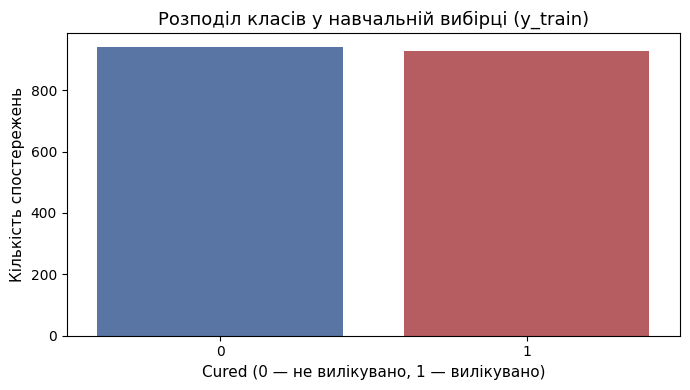

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(x=y_train, hue=y_train, palette=['#4c72b0', '#c44e52'], legend=False)
plt.title('Розподіл класів у навчальній вибірці (y_train)', fontsize=13)
plt.xlabel('Cured (0 — не вилікувано, 1 — вилікувано)', fontsize=11)
plt.ylabel('Кількість спостережень', fontsize=11)
plt.tight_layout()
plt.show()

**Висновок:**  
**Чи збалансовані класи:** так, класи в навчальній вибірці є повністю збалансованими — клас 0 містить 941 спостереження (50.32%), а клас 1 — 929 спостережень (49.68%). Розподіл практично досягає ідеального співвідношення 1:1.


**Вплив на оцінку моделі:** відсутність дисбалансу означає, що метрика *Accuracy* буде об'єктивним і надійним показником якості, оскільки базовий випадковий прогноз дає 50%, і модель не зможе штучно завищити точність за рахунок передбачення лише домінуючого класу. Крім того, алгоритми навчання не матимуть зміщення (bias) у бік одного з наслідків, тому немає потреби застосовувати балансувальні ваги (class_weight='balanced') або методи штучного ресемплінгу (SMOTE, undersampling).

### 6. Дослідження викидів на навчальних даних


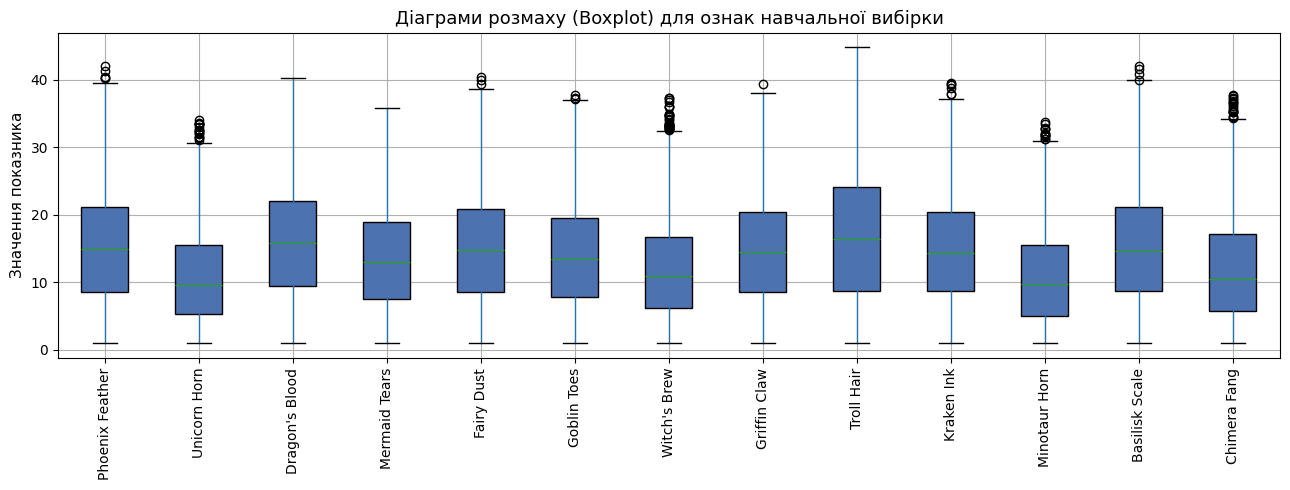

In [11]:
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90, patch_artist=True, boxprops=dict(facecolor='#4c72b0', color='black'))
plt.title('Діаграми розмаху (Boxplot) для ознак навчальної вибірки', fontsize=13)
plt.ylabel('Значення показника', fontsize=11)
plt.tight_layout()
plt.show()

In [12]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers_count = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outliers_sorted = outliers_count.sort_values(ascending=False)
print("Кількість потенційних викидів за правилом 1.5 IQR:")
display(outliers_sorted)

Кількість потенційних викидів за правилом 1.5 IQR:


,0
Witch's Brew,31
Chimera Fang,18
Unicorn Horn,17
Minotaur Horn,13
Kraken Ink,6
Phoenix Feather,5
Basilisk Scale,4
Fairy Dust,3
Goblin Toes,3
Griffin Claw,1


**Висновок про викиди:**  
**У яких ознаках їх найбільше:** найбільшу кількість потенційних викидів виявлено в ознаках Witch's Brew (31 спостереження), Chimera Fang (18 спостережень), Unicorn Horn (17 спостережень) та Minotaur Horn (13 спостережень). В інших ознаках кількість викидів мінімальна (від 1 до 6), а в трьох ознаках (Dragon's Blood, Mermaid Tears, Troll Hair) статистичних викидів за правилом $1.5 \times \text{IQR}$ взагалі немає.

***Чому не варто без перевірки видаляти всі такі рядки:***

**Втрата цінної інформації:** ці точки не є помилками вимірювання чи збоями запису — це природні максимальні концентрації рідкісних магічних компонентів, які можуть мати вирішальний вплив на факт зцілення принцеси.

**Кумулятивна втрата даних:** якщо видалити кожен рядок, де хоча б один компонент перевищує поріг, ми безповоротно втратимо суттєву частку навчальної вибірки та ризикуємо порушити баланс класів.

**Стійкість моделей:** алгоритми на зразок дерев рішень (Decision Tree) взагалі інваріантні до монотонних перетворень і викидів, а для логістичної регресії та SVM проблему масштабів і надмірного впливу великих значень набагато ефективніше вирішувати за допомогою масштабування (наприклад, StandardScaler або RobustScaler) та $L_1/L_2$-регуляризації.

### 7. Кореляційний аналіз на навчальній вибірці


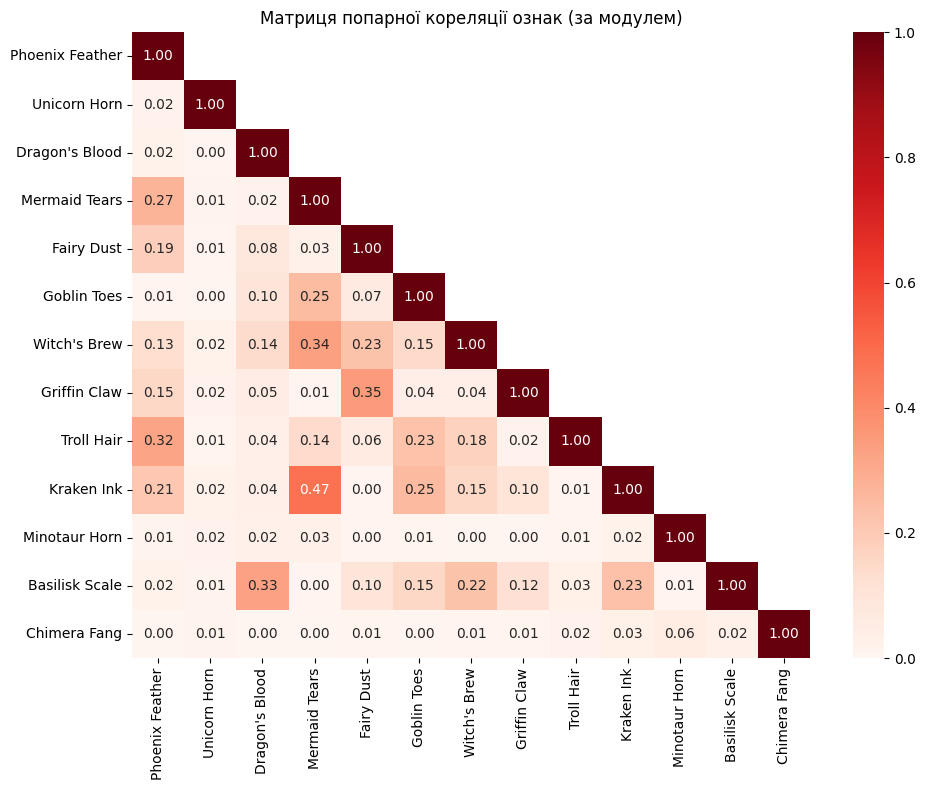

In [13]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap='Reds',
    vmin=0,
    vmax=1,
)
plt.title('Матриця попарної кореляції ознак (за модулем)')
plt.tight_layout()
plt.show()

In [14]:
train_data = pd.concat([X_train, y_train], axis=1)
corr_with_target = train_data.corr()['Cured'].drop('Cured')
target_corr_df = pd.DataFrame({
    'Кореляція (r)': corr_with_target,
    'Модуль (|r|)': corr_with_target.abs()
}).sort_values(by='Модуль (|r|)', ascending=False)

print("Кореляція ознак із цільовою змінною Cured (відсортовано за модулем):")
display(target_corr_df.round(4))

Кореляція ознак із цільовою змінною Cured (відсортовано за модулем):


,Кореляція (r),Модуль (|r|)
Troll Hair,0.5040,0.5040
Witch's Brew,0.2377,0.2377
Basilisk Scale,-0.0551,0.0551
Goblin Toes,0.0499,0.0499
Kraken Ink,-0.0371,0.0371
Phoenix Feather,0.0241,0.0241
Unicorn Horn,-0.0220,0.0220
Griffin Claw,-0.0205,0.0205
Chimera Fang,0.0182,0.0182
Dragon's Blood,0.0167,0.0167


**Висновок про кореляції:**  

**Пари найбільш корельованих між собою ознак:**

* **Kraken Ink та Mermaid Tears:** $\vert{}r\vert{} = 0.47$ (найвища попарна кореляція серед усіх ознак).

* **Griffin Claw та Fairy Dust:** $\vert{}r\vert{} = 0.35$.

* **Witch's Brew та Mermaid Tears:** $\vert{}r\vert{} = 0.34$.

* **Basilisk Scale та Dragon's Blood:** $\vert{}r\vert{} = 0.33$.

* **Troll Hair та Phoenix Feather:** $\vert{}r\vert{} = 0.32$.

Усі коефіцієнти між ознаками не перевищують $0.50$, що свідчить про помірний зв'язок і відсутність небезпечної мультиколінеарності (коли $\vert{}r\vert{} > 0.8$).

* **Ознаки з найсильнішим зв’язком із цільовою змінною `Cured`:**

* **Troll Hair:** помітна позитивна лінійна кореляція $r = 0.5040$ ($\vert{}r\vert{} = 0.5040$), що робить цей інгредієнт найважливішим лінійним предиктором успішного лікування.

* **Witch's Brew:** помірна позитивна кореляція $r = 0.2377$ ($\vert{}r\vert{} = 0.2377$).

* Решта ознак демонструють слабкий лінійний зв'язок із цільовою змінною ($\vert{}r\vert{} \le 0.0551$, де найбільшими серед них є **Basilisk Scale** з $r = -0.0551$ та **Goblin Toes** з $r = 0.0499$). Це вказує на те, що лінійна модель переважно спиратиметься на волосся троля та зілля відьми, тоді як інші інгредієнти можуть проявляти складніші нелінійні взаємодії.

### 8. Стандартизація ознак


In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія


In [16]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8526

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів


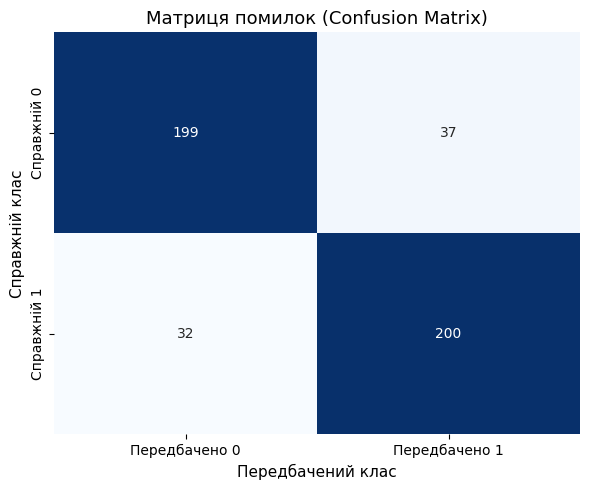

In [17]:
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    conf,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Передбачено 0', 'Передбачено 1'],
    yticklabels=['Справжній 0', 'Справжній 1']
)
plt.title('Матриця помилок (Confusion Matrix)', fontsize=13)
plt.ylabel('Справжній клас', fontsize=11)
plt.xlabel('Передбачений клас', fontsize=11)
plt.tight_layout()
plt.show()

In [18]:
comparison_df = pd.DataFrame({
    'Справжній клас': y_test.values,
    'Передбачений клас': y_pred
}, index=y_test.index)
comparison_df['Збіг'] = comparison_df['Справжній клас'] == comparison_df['Передбачений клас']
sample_10 = comparison_df.sample(10, random_state=42)
display(sample_10)

,Справжній клас,Передбачений клас,Збіг
1318,0,0,True
244,0,0,True
996,1,1,True
930,0,0,True
839,0,0,True
1251,1,1,True
335,1,1,True
1670,0,0,True
1118,0,0,True
2175,1,1,True


**Висновок щодо якості логістичної регресії:**  
**Яких помилок більше:**
* Помилок першого роду (**False Positive**, коли справжній $0$, але передбачено $1$) — **37** спостережень.
* Помилок другого роду (**False Negative**, коли справжній $1$, але передбачено $0$) — **32** спостереження.
Отже, модель частіше допускає помилки першого роду (хибне зцілення, коли принцесу позначено як вилікувану, хоча це не так). Водночас кількість помилок обох типів є досить близькою (37 проти 32), що вказує на симетричність класифікатора.

**Чи достатньо однієї метрики Accuracy:**
* Лише метрики **Accuracy** недостатньо, навіть попри баланс класів у вибірці. Вона показує лише загальну частку правильних відповідей ($\frac{199 + 200}{199 + 37 + 32 + 200} \approx 85.26\%$), але не дає інформації про структуру та ціну помилок.

* У медичних і життєво важливих задачах (як лікування) помилка другого роду (FN — не помітити хворобу і вважати принцесу невилікуваною) та помилка першого роду (FP — вирішити, що зілля спрацювало, коли це не так) мають різну критичність. Тому обов'язково потрібно контролювати **Precision**, **Recall** та інтегральну метрику **F1-score**, а також аналізувати матрицю помилок.

### 11. Підбір гіперпараметрів


In [19]:
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 500]
}
param_dist = {
    'C': np.logspace(-3, 2, 20),
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [100, 200, 300, 500, 1000]
}

In [20]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)
print("--- Результати GridSearchCV ---")
print(f"Найкращі параметри: {grid_search.best_params_}")
print(f"Найкраща точність (CV Accuracy): {grid_search.best_score_:.4f}")

--- Результати GridSearchCV ---
Найкращі параметри: {'C': 10.0, 'max_iter': 100, 'solver': 'lbfgs'}
Найкраща точність (CV Accuracy): 0.8749


In [21]:
random_search = RandomizedSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)
print("--- Результати RandomizedSearchCV ---")
print(f"Найкращі параметри: {random_search.best_params_}")
print(f"Найкраща точність (CV Accuracy): {random_search.best_score_:.4f}")

--- Результати RandomizedSearchCV ---
Найкращі параметри: {'solver': 'lbfgs', 'max_iter': 1000, 'C': np.float64(8.858667904100823)}
Найкраща точність (CV Accuracy): 0.8749


In [24]:
best_lr_model = grid_search.best_estimator_
y_pred_best = best_lr_model.predict(X_test_scaled)
acc_best = accuracy_score(y_test, y_pred_best)
print(f"Accuracy найкращої моделі на тесті: {acc_best:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_best))

Accuracy найкращої моделі на тесті: 0.8504

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**  
**Який метод пошуку обрав які параметри:**

* **GridSearchCV:** обрав параметри `{'C': 10.0, 'max_iter': 100, 'solver': 'lbfgs'}` із точністю на крос-валідації $\approx 0.8749$ ($87.49\%$).

* **RandomizedSearchCV:** обрав практично ідентичну конфігурацію — `{'solver': 'lbfgs', 'max_iter': 1000, 'C': 8.8587}` із точно такою самою точністю крос-валідації ($0.8749$). Обидва методи зійшлися на тому, що оптимізатор `lbfgs` та дещо слабша регуляризація ($C \approx 8.86\dots10.0$ замість стандартного $C=1.0$) є оптимальними для цього набору ознак.

**Чи покращилась якість порівняно з базовою моделлю:**

* На тестовій вибірці точність оптимізованої моделі склала **0.8504** ($85.04\%$), тоді як базова модель без налаштування гіперпараметрів показувала **0.8526** ($85.26\%$).

* Істотного приросту якості не відбулося (різниця становить лише один неправильно класифікований приклад). Це типова поведінка для логістичної регресії: оскільки це лінійна модель із невеликою кількістю налаштовуваних параметрів, її розділяюча гіперплощина досягає своєї межі виразності вже на базових значеннях за умови попередньо стандартизованих даних. Для суттєвого підвищення якості необхідно переходити до нелінійних моделей (SVM із RBF-ядром або Decision Tree).

### 12. Порівняння трьох моделей


In [25]:
models = {
    'Logistic Regression': LogisticRegression(C=10.0, solver='lbfgs', max_iter=100, random_state=42),
    'SVC': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

results = []
for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred_m = clf.predict(X_test_scaled)

    acc_m = accuracy_score(y_test, y_pred_m)
    f1_m = f1_score(y_test, y_pred_m)

    results.append({
        'Модель': name,
        'Accuracy': round(acc_m, 4),
        'F1-score': round(f1_m, 4)
    })
comparison_models_df = pd.DataFrame(results).sort_values(by='F1-score', ascending=False).reset_index(drop=True)
display(comparison_models_df)
best_model_name = comparison_models_df.iloc[0]['Модель']
best_f1 = comparison_models_df.iloc[0]['F1-score']
print(f"Найкраща модель за F1-score: {best_model_name} (F1 = {best_f1})")

,Модель,Accuracy,F1-score
0,SVC,0.9338,0.9328
1,Logistic Regression,0.8504,0.8504
2,Decision Tree,0.8248,0.8240


Найкраща модель за F1-score: SVC (F1 = 0.9328)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
1. **Особливості даних під час первинного аналізу:** вибірка містить 2338 спостережень та 14 ознак (13 числових предикторів магічних інгредієнтів типу `float64` і бінарну цільову змінну `Cured` типу `int64`). У датасеті повністю відсутні пропущені значення та дублікати рядків. Класи цільової змінної практично ідеально збалансовані (50.32% класу `0` та 49.68% класу `1`), що дозволяє об'єктивно використовувати метрику Accuracy без ризику зміщення моделі. Ознаки мають різні діапазони значень, тому їх стандартизація була обов'язковою для метричних і лінійних алгоритмів.

2. **Дослідження викидів і кореляцій на навчальній вибірці:**
* *Викиди:* за правилом $1.5 \times \text{IQR}$ потенційні викиди зафіксовано переважно у 4 ознаках (**Witch's Brew** — 31, **Chimera Fang** — 18, **Unicorn Horn** — 17, **Minotaur Horn** — 13), тоді як в інших їхня кількість мізерна або нульова. Їх не видаляли, оскільки це валідні екстремальні дозування інгредієнтів, втрата яких погіршила б узагальнюючу здатність моделей.

* *Кореляції:* найвища попарна кореляція між ознаками склала $\vert{}r\vert{} = 0.47$ (**Kraken Ink** та **Mermaid Tears**), що свідчить про відсутність небезпечної мультиколінеарності. З цільовою змінною `Cured` найбільш помітний позитивний лінійний зв'язок показали **Troll Hair** ($r = 0.5040$) та **Witch's Brew** ($r = 0.2377$), тоді як решта ознак мають низькі лінійні коефіцієнти ($\vert{}r\vert{} \le 0.0551$).

3. **Якість базової логістичної регресії:** на стандартизованій тестовій вибірці модель показала **Accuracy = 0.8526** та **F1-score = 0.85**. Матриця помилок виявила 37 помилок типу False Positive та 32 помилки типу False Negative, демонструючи збалансовану точність без істотного перекосу в бік жодного з класів.

4. **Вплив підбору гіперпараметрів:** `GridSearchCV` та `RandomizedSearchCV` виявили однакову оптимальну конфігурацію параметрів (`solver='lbfgs'`, дещо послаблена регуляризація $C \approx 8.86\dots10.0$ замість стандартного $C=1.0$), досягнувши крос-валідаційної точності $87.49\%$. На відкладеному тесті якість склала **Accuracy = 0.8504** та **F1-score = 0.8504**. Суттєвого стрибка метрик не відбулося, що свідчить про вичерпання роздільної здатності лінійної гіперплощини для заданих даних.

5. **Найкраща модель та обґрунтування:** найкращою моделлю виявився **метод опорних векторів (SVC)**, показавши суттєво вищі результати на тестовій вибірці: **Accuracy = 0.9338** та **F1-score = 0.9328** (проти 0.8504 у Logistic Regression та 0.8248 у одиночного Decision Tree). Завдяки використанню RBF-ядра (радіально-базисної функції) SVC ефективно спроєктував простір ознак у вимір, де виявив складні нелінійні комбінації магічних інгредієнтів, які прості лінійні межі логістичної регресії та схильні до перенавчання розбиття одиничного дерева рішень врахувати не здатні.

